In [1]:
import pandas as pd
import csv

def robust_load_csv(file_path):
    """
    Robustly load a CSV:
    - Reads any number of tag columns (even with commas inside)
    - Merges them into one 'tags' column
    - Guarantees consistent column count
    """
    with open(file_path, "r", encoding="utf-8") as f:
        reader = csv.reader(f)
        rows = list(reader)

    header = rows[0]
    # Find indices for the columns we know are fixed
    start_idx = header.index("oldRating") + 1
    end_idx = header.index("solveTime")
    
    # Calculate the number of columns that should come AFTER the tags
    num_suffix_cols = len(header) - end_idx

    processed_rows = []
    for row in rows[1:]:
        # Define the parts of the row based on the fixed columns
        prefix_data = row[:start_idx]
        
        # Use negative indexing to correctly find the suffix columns
        # This works even if the total number of columns in `row` is unexpected
        suffix_data = row[-num_suffix_cols:] if num_suffix_cols > 0 else []
        
        # The tags are everything in between the prefix and suffix
        # Handle the edge case where there are no suffix columns
        if num_suffix_cols > 0:
            tags_raw = row[start_idx:-num_suffix_cols]
        else:
            tags_raw = row[start_idx:]
            
        tags = [t.strip() for t in tags_raw if t.strip()]

        # Rebuild the row with a consistent structure
        new_row = prefix_data + [tags] + suffix_data
        processed_rows.append(new_row)

    # Build the corresponding clean header
    new_header = header[:start_idx] + ["tags"] + header[end_idx:]

    return pd.DataFrame(processed_rows, columns=new_header)

def process_df(df):
    """
    Adds timeDiff per handle+contestId.
    """
    df = df.copy()
    df["solveTime"] = df["solveTime"].astype(int)
    df["timeDiff"] = pd.NA

    # Using transform is more idiomatic and often faster than iterating
    df = df.sort_values(by=["handle", "contestId", "solveTime"])
    df['timeDiff'] = df.groupby(["handle", "contestId"])['solveTime'].diff().fillna(df['solveTime'])
    df['timeDiff'] = df['timeDiff'].astype(int)
    
    return df

if __name__ == "__main__":
    df_input = robust_load_csv("data.csv")
    df_with_diffs = process_df(df_input)
    df_with_diffs.to_csv("processed_data.csv", index=False)
    print("✅ Processed CSV saved as 'processed_data.csv'")

✅ Processed CSV saved as 'processed_data.csv'


In [2]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast # To safely evaluate string-represented lists



In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MultiLabelBinarizer

# Set plot style for better visuals
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load the processed data
df = pd.read_csv("processed_data.csv")

# --- Critical Step: Convert comma-separated string to a list of tags ---
# We fill NaNs with an empty string to prevent errors, then split by comma.
# A list comprehension cleans up any leading/trailing whitespace from each tag.
df['tags'] = df['tags'].fillna('').apply(lambda x: [tag.strip() for tag in x.split(',') if tag.strip()])

# Select columns and set correct data types
df = df[['oldRating', 'rating', 'tags', 'timeDiff']].copy()
df.dropna(inplace=True)
df['oldRating'] = df['oldRating'].astype(int)
df['rating'] = df['rating'].astype(int)

print("Shape after loading and initial cleaning:")
print(df.shape)
df.head()


Shape after loading and initial cleaning:
(157187, 4)


,oldRating,rating,tags,timeDiff
0,0,800,"[['constructive algorithms', 'greedy']]",688
1,1066,800,"[['constructive algorithms', 'greedy']]",915
2,1066,1100,"[['greedy', 'math']]",1823
3,1029,800,"[['greedy', 'sortings']]",1119
4,1029,1000,[['greedy']],3022


In [4]:
rating_gap = df['rating'] - df['oldRating']
# Remove submissions where the problem is rated 400+ points above the user
df = df[rating_gap <= 400]

# 2. Filter by timeDiff to remove noise
# Remove submissions faster than 15 seconds (likely not genuine attempts)
df = df[df['timeDiff'] > 15]
# Remove the top 1% of the slowest submissions
time_cap = df['timeDiff'].quantile(0.99)
df = df[df['timeDiff'] <= time_cap]

print("\nShape after removing outliers:")
print(df.shape)

df.head()


Shape after removing outliers:
(144020, 4)


,oldRating,rating,tags,timeDiff
1,1066,800,"[['constructive algorithms', 'greedy']]",915
2,1066,1100,"[['greedy', 'math']]",1823
3,1029,800,"[['greedy', 'sortings']]",1119
4,1029,1000,[['greedy']],3022
5,1152,800,"[['constructive algorithms', 'greedy']]",411


In [5]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import mean_absolute_error, mean_squared_error
import time
import ast
import re

def clean_tags_v3(val):
    """Bulletproof flattener for nested lists/arrays/strings."""
    # Handle actual list/array types first to avoid truthiness errors
    if isinstance(val, (list, np.ndarray, tuple)):
        # Deep flatten
        items = []
        def _flatten(l):
            for i in l:
                if isinstance(i, (list, np.ndarray, tuple)): _flatten(i)
                else: items.append(str(i).strip())
        _flatten(val)
        return list(set(items))
    
    # Handle None or NaN for non-array types
    if pd.isna([val])[0]: # Safer scalar check
        return []
    
    # Handle strings that look like lists
    if isinstance(val, str):
        try:
            val_eval = ast.literal_eval(val.replace('[[', '[').replace(']]', ']'))
            return clean_tags_v3(val_eval)
        except:
            return [val.strip()]
            
    return [str(val).strip()]

# 1. Process Tags
df['tags_cleaned'] = df['tags'].apply(clean_tags_v3)

# 2. Multi-Hot Encoding
mlb = MultiLabelBinarizer()
tag_matrix = mlb.fit_transform(df['tags_cleaned'])
# Prefix tag names to prevent collisions with 'rating' or 'oldRating'
tag_cols = [f"tag_{re.sub(r'\W+', '_', c)}" for c in mlb.classes_]
tag_df = pd.DataFrame(tag_matrix, columns=tag_cols, index=df.index)

# 3. Build Feature Matrix X (Using specific prefixes for all columns)
X = pd.concat([
    df[['oldRating']].rename(columns={'oldRating': 'user_rating'}),
    df[['rating']].rename(columns={'rating': 'problem_rating'}),
    tag_df
], axis=1)

# 4. Final Sanitization (Remove duplicates and special characters for LightGBM)
X = X.loc[:, ~X.columns.duplicated()].copy()
y = df['timeDiff']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Final Dataset: {X_train.shape[0]} rows, {X_train.shape[1]} unique features.")

df.shape

features = X.columns.tolist()

print(f"Total Features: {len(features)}")
print("--- Full Feature List ---")
for i, feature in enumerate(features, 1):
    print(f"{i}. {feature}")



Final Dataset: 115216 rows, 24 unique features.
Total Features: 24
--- Full Feature List ---
1. user_rating
2. problem_rating
3. tag__brute_force_
4. tag__constructive_algorithms_
5. tag__data_structures_
6. tag__dfs_and_similar_
7. tag__divide_and_conquer_
8. tag__dp_
9. tag__fft_
10. tag__geometry_
11. tag__graphs_
12. tag__greedy_
13. tag__implementation_
14. tag__math_
15. tag__number_theory_
16. tag__shortest_paths_
17. tag__sortings_
18. tag__ternary_search_
19. tag__trees_
20. tag__two_pointers_
21. tag__binary_search_
22. tag__bitmasks_
23. tag__combinatorics_
24. tag__games_


Training on 115147 samples with 30 features...

--- ANALYTICAL RESULTS ---
Seconds MAE         : 716.7022
Seconds MedAE       : 431.6057
Seconds RMSE        : 1077.7515
R2 (Log Scale)      : 0.4028


/tmp/ipykernel_84500/1217674940.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feat_imp.values[:15], y=feat_imp.index[:15], palette='viridis')


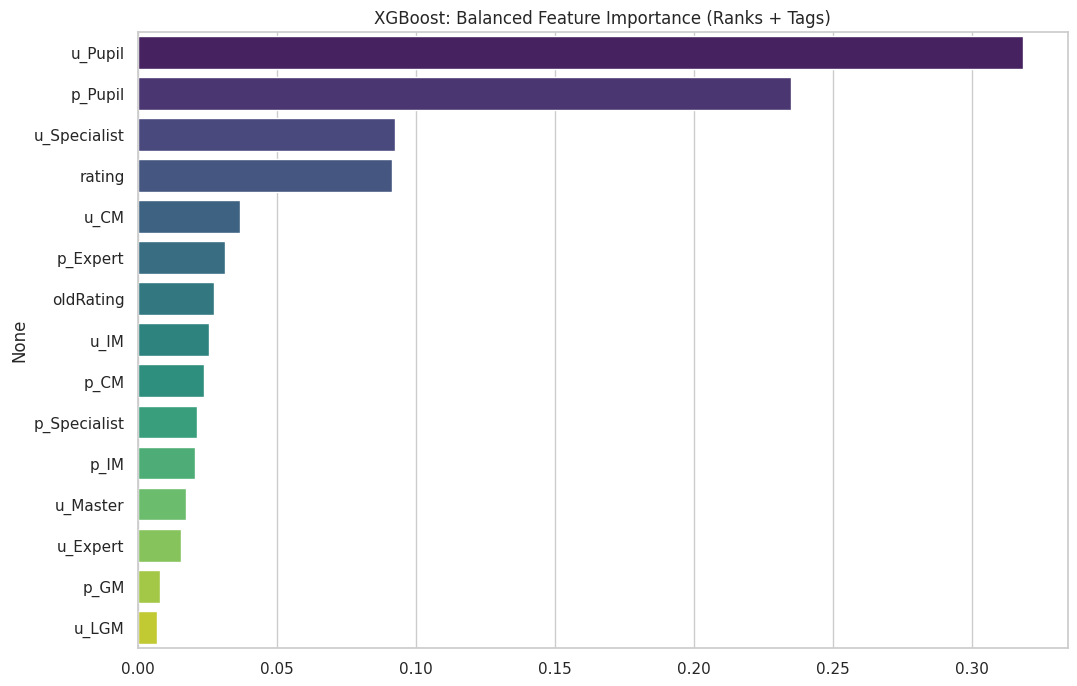

In [8]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, median_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import ast
import re
import time

# 1. CLEANING & TARGET TRANSFORMATION
# Predict log(1+x) to squash the long-tail variance of solve times
df_model = df.dropna(subset=['timeDiff', 'rating', 'oldRating']).copy()
df_model = df_model[(df_model['timeDiff'] > 30) & (df_model['timeDiff'] < 10800)]
df_model['log_target'] = np.log1p(df_model['timeDiff'])

# 2. RANK BUCKETING (Methodology to reduce Rating dominance)
bins = [0, 1199, 1399, 1599, 1899, 2099, 2299, 2399, 2599, 2999, 5000]
labels = ['Pupil', 'Specialist', 'Expert', 'CM', 'Master', 'IM', 'GM', 'IGM', 'LGM', 'Tourist']
df_model['u_rank'] = pd.cut(df_model['oldRating'], bins=bins, labels=labels)
df_model['p_rank'] = pd.cut(df_model['rating'], bins=bins, labels=labels)

# 3. TAG PROCESSING (Your logic for high-frequency tags)
target_tags = ['greedy', 'brute force', 'math', 'implementation', 'dp', 'bitmasks', 'binary search', 'constructive algorithms']
for tag in target_tags:
    col_name = f'tag_{tag.replace(" ", "_")}'
    df_model[col_name] = df_model['tags'].apply(
        lambda x: 1 if isinstance(x, str) and tag in [t.strip() for t in x.split(',')] else 0
    )

# 4. ONE-HOT ENCODING & FEATURE SELECTION
# One-hot encoding creates distinct logical states for each rank
df_model = pd.get_dummies(df_model, columns=['u_rank', 'p_rank'], prefix=['u', 'p'])

rank_cols = [c for c in df_model.columns if c.startswith('u_') or c.startswith('p_')]
tag_cols = [f'tag_{t.replace(" ", "_")}' for t in target_tags]
feature_cols = ['rating', 'oldRating'] + rank_cols + tag_cols

X = df_model[feature_cols].copy()
y = df_model['log_target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. MODEL TRAINING: XGBOOST
# Lowering colsample forces the model to use Tag features
xgb_reg = xgb.XGBRegressor(
    n_estimators=1000, learning_rate=0.05, max_depth=6, 
    subsample=0.8, colsample_bytree=0.6, tree_method='hist', random_state=42
)

print(f"Training on {X_train.shape[0]} samples with {len(feature_cols)} features...")
xgb_reg.fit(X_train, y_train)

# 6. ANALYTICAL EVALUATION
y_pred_log = xgb_reg.predict(X_test)
y_test_orig = np.expm1(y_test)
y_pred_orig = np.expm1(y_pred_log)

metrics = {
    "Seconds MAE": mean_absolute_error(y_test_orig, y_pred_orig),
    "Seconds MedAE": median_absolute_error(y_test_orig, y_pred_orig),
    "Seconds RMSE": np.sqrt(mean_squared_error(y_test_orig, y_pred_orig)),
    "R2 (Log Scale)": r2_score(y_test, y_pred_log)
}

print("\n--- ANALYTICAL RESULTS ---")
for k, v in metrics.items():
    print(f"{k:20}: {v:.4f}")

# 7. FEATURE IMPORTANCE VISUALIZATION
plt.figure(figsize=(12, 8))
feat_imp = pd.Series(xgb_reg.feature_importances_, index=feature_cols).sort_values(ascending=False)
sns.barplot(x=feat_imp.values[:15], y=feat_imp.index[:15], palette='viridis')
plt.title("XGBoost: Balanced Feature Importance (Ranks + Tags)")
plt.show()

/tmp/ipykernel_84500/3621514827.py:35: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_norm = df_model.groupby('p_rank', observed=True).apply(normalize_counts).reset_index(drop=True)


Normalized Dataset Size: 81776 (Targeting 40k start and decreasing)

--- NORMALIZED MODEL PERFORMANCE ---
MAE: 790.25s
MedAE: 508.71s
R2 (Log Scale): 0.4247


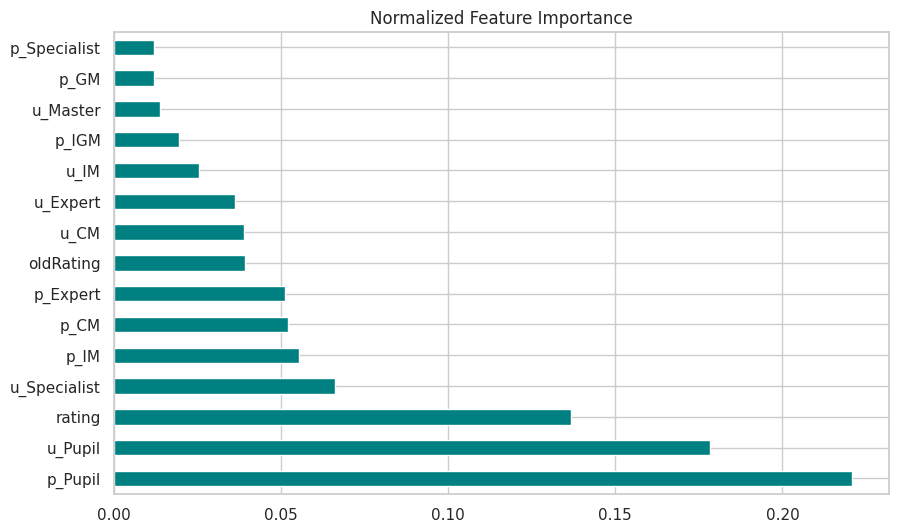

In [9]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, median_absolute_error, 
    mean_squared_error, r2_score, mean_squared_log_error
)
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. RANK BUCKETING & NORMALIZATION (SAMPLING)
# ==========================================
# Official CF Rank Thresholds
bins = [0, 1199, 1399, 1599, 1899, 2099, 2299, 2399, 2599, 2999, 5000]
labels = ['Pupil', 'Specialist', 'Expert', 'CM', 'Master', 'IM', 'GM', 'IGM', 'LGM', 'Tourist']

# Normalize target counts per bucket (decreasing as requested)
norm_targets = {
    'Pupil': 40000, 'Specialist': 25000, 'Expert': 15000, 'CM': 10000, 
    'Master': 7000, 'IM': 4000, 'GM': 2000, 'IGM': 1000, 'LGM': 500, 'Tourist': 200
}

df_model = df.dropna(subset=['timeDiff', 'rating', 'oldRating']).copy()
df_model = df_model[(df_model['timeDiff'] > 30) & (df_model['timeDiff'] < 10800)]
df_model['p_rank'] = pd.cut(df_model['rating'], bins=bins, labels=labels)

# Perform Normalization via Sampling
def normalize_counts(group):
    target = norm_targets.get(group.name, 100)
    return group.sample(n=min(len(group), target), random_state=42)

df_norm = df_model.groupby('p_rank', observed=True).apply(normalize_counts).reset_index(drop=True)
print(f"Normalized Dataset Size: {len(df_norm)} (Targeting 40k start and decreasing)")

# ==========================================
# 2. FEATURE ENGINEERING
# ==========================================
df_norm['log_target'] = np.log1p(df_norm['timeDiff'])
df_norm['u_rank'] = pd.cut(df_norm['oldRating'], bins=bins, labels=labels)

# Process 'Big Five' Tags
target_tags = ['greedy', 'brute force', 'math', 'implementation', 'dp']
for tag in target_tags:
    col_name = f'tag_{tag.replace(" ", "_")}'
    df_norm[col_name] = df_norm['tags'].apply(
        lambda x: 1 if isinstance(x, str) and tag in [t.strip() for t in x.split(',')] else 0
    )

# One-Hot Encoding for Ranks
df_norm = pd.get_dummies(df_norm, columns=['u_rank', 'p_rank'], prefix=['u', 'p'])

rank_cols = [c for c in df_norm.columns if c.startswith('u_') or c.startswith('p_')]
tag_cols = [f'tag_{t.replace(" ", "_")}' for t in target_tags]
feature_cols = ['rating', 'oldRating'] + rank_cols + tag_cols

X = df_norm[feature_cols]
y = df_norm['log_target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ==========================================
# 3. TRAINING & EVALUATION
# ==========================================
xgb_reg = xgb.XGBRegressor(n_estimators=1000, learning_rate=0.05, max_depth=6, 
                           subsample=0.8, colsample_bytree=0.6, tree_method='hist', random_state=42)

xgb_reg.fit(X_train, y_train)

# Evaluation
y_pred_log = xgb_reg.predict(X_test)
y_true_sec = np.expm1(y_test)
y_pred_sec = np.expm1(y_pred_log)

print("\n--- NORMALIZED MODEL PERFORMANCE ---")
print(f"MAE: {mean_absolute_error(y_true_sec, y_pred_sec):.2f}s")
print(f"MedAE: {median_absolute_error(y_true_sec, y_pred_sec):.2f}s")
print(f"R2 (Log Scale): {r2_score(y_test, y_pred_log):.4f}")

# Visualize the new balanced importance
plt.figure(figsize=(10, 6))
feat_imp = pd.Series(xgb_reg.feature_importances_, index=feature_cols).sort_values(ascending=False)
feat_imp.head(15).plot(kind='barh', color='teal')
plt.title("Normalized Feature Importance")
plt.show()

In [11]:
import pandas as pd
import numpy as np
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import mean_absolute_error, median_absolute_error, r2_score
import ast
import re

# 1. TAG CLEANING
def clean_tags_v4(val):
    if isinstance(val, (list, np.ndarray, tuple)):
        items = []
        def _flatten(l):
            for i in l:
                if isinstance(i, (list, np.ndarray, tuple)): _flatten(i)
                else: items.append(str(i).strip())
        _flatten(val)
        return list(set(items))
    if pd.isna([val])[0]: return []
    if isinstance(val, str):
        try:
            val_eval = ast.literal_eval(val.replace('[[', '[').replace(']]', ']'))
            return clean_tags_v4(val_eval)
        except: return [val.strip()]
    return [str(val).strip()]

# 2. PREPROCESSING & NORMALIZATION
df_model = df.dropna(subset=['timeDiff', 'rating', 'oldRating']).copy()
df_model = df_model[(df_model['timeDiff'] > 30) & (df_model['timeDiff'] < 10800)]
df_model['log_target'] = np.log1p(df_model['timeDiff'])

# Create sampling bins
bins = [0, 1199, 1399, 1599, 1899, 2099, 2299, 2399, 2599, 2999, 5000]
labels = ['Pupil', 'Specialist', 'Expert', 'CM', 'Master', 'IM', 'GM', 'IGM', 'LGM', 'Tourist']
df_model['p_rank'] = pd.cut(df_model['rating'], bins=bins, labels=labels)

norm_targets = {'Pupil': 40000, 'Specialist': 25000, 'Expert': 15000, 'CM': 10000, 
                'Master': 7000, 'IM': 4000, 'GM': 2000, 'IGM': 1000, 'LGM': 500, 'Tourist': 200}

def normalize_by_rank(group):
    target = norm_targets.get(group.name, 100)
    return group.sample(n=min(len(group), target), random_state=42)

df_norm = df_model.groupby('p_rank', observed=True).apply(normalize_by_rank).reset_index(drop=True)

# 3. FEATURE ENGINEERING (ALL TAGS)
df_norm['tags_cleaned'] = df_norm['tags'].apply(clean_tags_v4)
mlb = MultiLabelBinarizer()
tag_matrix = mlb.fit_transform(df_norm['tags_cleaned'])
# Prefixing "tag_" prevents collisions with columns like 'rating'
tag_cols = [f"tag_{re.sub(r'\W+', '_', c)}" for c in mlb.classes_]
tag_df = pd.DataFrame(tag_matrix, columns=tag_cols, index=df_norm.index)

# Build X and Y
X = pd.concat([df_norm[['oldRating', 'rating']], tag_df], axis=1)
# CRITICAL FIX: Ensure no duplicate columns which break XGBoost
X = X.loc[:, ~X.columns.duplicated()].copy()
y = df_norm['log_target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. TUNING FUNCTION
def tune_and_train(model, params, X_data, y_data, name):
    print(f"\nStarting Tuning for {name}...")
    # Using error_score='raise' helps debug if the model fails again
    search = RandomizedSearchCV(model, param_distributions=params, n_iter=10, 
                                cv=3, scoring='neg_mean_absolute_error', 
                                n_jobs=-1, verbose=1, error_score='raise')
    search.fit(X_data, y_data)
    return search.best_estimator_

# Grids
xgb_params = {'n_estimators': [500, 1000], 'max_depth': [5, 7], 'learning_rate': [0.05, 0.1], 
              'colsample_bytree': [0.6, 0.8], 'reg_lambda': [1, 10]}
lgb_params = {'n_estimators': [500, 1000], 'num_leaves': [31, 63], 'learning_rate': [0.05, 0.1],
              'feature_fraction': [0.7, 0.9]}

# Execution
best_xgb = tune_and_train(xgb.XGBRegressor(tree_method='hist', random_state=42), xgb_params, X_train, y_train, "XGBoost")
best_lgb = tune_and_train(lgb.LGBMRegressor(random_state=42, verbose=-1), lgb_params, X_train, y_train, "LightGBM")

# 5. EVALUATION
def evaluate_final(model, X_val, y_val, name):
    preds = np.expm1(model.predict(X_val))
    actuals = np.expm1(y_val)
    print(f"\n[{name}] MAE: {mean_absolute_error(actuals, preds):.2f}s | MedAE: {median_absolute_error(actuals, preds):.2f}s | R2: {r2_score(y_val, model.predict(X_val)):.4f}")

evaluate_final(best_xgb, X_test, y_test, "XGBoost")
evaluate_final(best_lgb, X_test, y_test, "LightGBM")

/tmp/ipykernel_84500/2784227063.py:46: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_norm = df_model.groupby('p_rank', observed=True).apply(normalize_by_rank).reset_index(drop=True)



Starting Tuning for XGBoost...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Starting Tuning for LightGBM...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

[XGBoost] MAE: 779.65s | MedAE: 503.78s | R2: 0.4448

[LightGBM] MAE: 780.26s | MedAE: 504.39s | R2: 0.4449
